# Notebook 4 — Issue and Sub-Issue Taxonomy

## Objective

This notebook develops a structured business taxonomy for CFPB complaint issues and sub-issues. Detailed complaint labels are grouped into broader themes that can support sentiment analysis, topic modelling, dashboards and financial-intelligence reporting.

The notebook uses the cleaned datasets produced in Notebook 2 and does not repeat data cleaning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

sns.set_theme(style="whitegrid")

## 1. Load Cleaned Datasets

The full cleaned dataset is used to build and validate the taxonomy. The balanced dataset will receive the same taxonomy so it can be used in later equal-product and NLP comparisons.

In [3]:
DATA_DIR = Path("../data/processed")

full_df = pd.read_csv(
    DATA_DIR / "cleaned_full_data.csv",
    low_memory=False
)

balanced_df = pd.read_csv(
    DATA_DIR / "balanced_analytical_data.csv",
    low_memory=False
)

print("Full cleaned dataset:", full_df.shape)
print("Balanced dataset:", balanced_df.shape)

Full cleaned dataset: (566694, 26)
Balanced dataset: (144697, 26)


## 2. Issue and Sub-Issue Inventory

Before creating broader themes, the existing CFPB issue structure is examined. This establishes the number of unique issues, sub-issues and issue–sub-issue combinations that require classification.

In [4]:
taxonomy_profile = pd.Series({
    "Total complaints": len(full_df),
    "Products": full_df["product"].nunique(),
    "Unique issues": full_df["issue"].nunique(),
    "Unique sub-issues": full_df["sub_issue"].nunique(),
    "Missing issues": full_df["issue"].isna().sum(),
    "Missing sub-issues": full_df["sub_issue"].isna().sum(),
    "Unique issue–sub-issue combinations": (
        full_df[["issue", "sub_issue"]]
        .drop_duplicates()
        .shape[0]
    )
})

display(taxonomy_profile.to_frame("value"))

,value
Total complaints,566694
Products,5
Unique issues,47
Unique sub-issues,135
Missing issues,0
Missing sub-issues,84777
Unique issue–sub-issue combinations,156


In [5]:
issue_inventory = (
    full_df
    .groupby(["product", "issue"])
    .size()
    .reset_index(name="complaints")
    .sort_values(
        ["product", "complaints"],
        ascending=[True, False]
    )
)

for product in issue_inventory["product"].unique():
    print(f"\nPRODUCT: {product}")

    display(
        issue_inventory[
            issue_inventory["product"] == product
        ].reset_index(drop=True)
    )


PRODUCT: Checking or savings account


,product,issue,complaints
0,Checking or savings account,Managing an account,44959
1,Checking or savings account,Problem caused by your funds being low,11939
2,Checking or savings account,Closing an account,10177
3,Checking or savings account,Problem with a lender or other company charging your account,9609
4,Checking or savings account,Opening an account,6957
5,Checking or savings account,Incorrect information on your report,224
6,Checking or savings account,Problem with a company's investigation into an existing problem,169
7,Checking or savings account,Improper use of your report,64
8,Checking or savings account,Problem with fraud alerts or security freezes,51
9,Checking or savings account,Credit monitoring or identity theft protection services,35



PRODUCT: Credit card


,product,issue,complaints
0,Credit card,Problem with a purchase shown on your statement,19810
1,Credit card,Incorrect information on your report,13735
2,Credit card,Getting a credit card,10805
3,Credit card,Problem with a company's investigation into an existing problem,10126
4,Credit card,"Other features, terms, or problems",8416
5,Credit card,Fees or interest,7836
6,Credit card,Closing your account,6224
7,Credit card,Problem when making payments,4597
8,Credit card,"Advertising and marketing, including promotional offers",3105
9,Credit card,Trouble using your card,3020



PRODUCT: Debt collection


,product,issue,complaints
0,Debt collection,Attempts to collect debt not owed,115682
1,Debt collection,Written notification about debt,64049
2,Debt collection,Took or threatened to take negative or legal action,48578
3,Debt collection,False statements or representation,38462
4,Debt collection,Communication tactics,9519
5,Debt collection,Electronic communications,4312
6,Debt collection,Threatened to contact someone or share information improperly,2603



PRODUCT: Money transfer, virtual currency, or money service


,product,issue,complaints
0,"Money transfer, virtual currency, or money service",Other transaction problem,53893
1,"Money transfer, virtual currency, or money service",Fraud or scam,11179
2,"Money transfer, virtual currency, or money service",Unauthorized transactions or other transaction problem,5758
3,"Money transfer, virtual currency, or money service",Trouble accessing funds in your mobile or digital wallet,3038
4,"Money transfer, virtual currency, or money service",Money was not available when promised,2429
5,"Money transfer, virtual currency, or money service",Other service problem,2064
6,"Money transfer, virtual currency, or money service",Confusing or missing disclosures,1970
7,"Money transfer, virtual currency, or money service","Managing, opening, or closing your mobile wallet account",1773
8,"Money transfer, virtual currency, or money service",Unexpected or other fees,647
9,"Money transfer, virtual currency, or money service",Problem with customer service,547



PRODUCT: Mortgage


,product,issue,complaints
0,Mortgage,Trouble during payment process,12680
1,Mortgage,Struggling to pay mortgage,5980
2,Mortgage,Applying for a mortgage or refinancing an existing mortgage,2597
3,Mortgage,Closing on a mortgage,2051
4,Mortgage,Incorrect information on your report,785
5,Mortgage,Problem with a company's investigation into an existing problem,448
6,Mortgage,Improper use of your report,88
7,Mortgage,Credit monitoring or identity theft protection services,34
8,Mortgage,Unable to get your credit report or credit score,19
9,Mortgage,Problem with fraud alerts or security freezes,15


### Credit Card Issue Profile

Credit card complaints are distributed across several issue types rather than being dominated by one category. The most common issue is **“Problem with a purchase shown on your statement”**, with 19,810 complaints. Other major concerns involve incorrect credit-report information, obtaining a credit card, company investigations, fees or interest, and account closure.

This distribution suggests that the credit card taxonomy will need to represent several distinct themes, including transaction disputes, credit reporting, account acquisition, complaint handling, pricing and fees, account management, and payment difficulties.

At this stage, these results are being inspected only. The original issue labels have not yet been modified or grouped.

In [6]:
# Review issue inventory for the next product
next_product = "Checking or savings account"

checking_issue_inventory = (
    issue_inventory[
        issue_inventory["product"].eq(next_product)
    ]
    .reset_index(drop=True)
)

display(checking_issue_inventory)

,product,issue,complaints
0,Checking or savings account,Managing an account,44959
1,Checking or savings account,Problem caused by your funds being low,11939
2,Checking or savings account,Closing an account,10177
3,Checking or savings account,Problem with a lender or other company charging your account,9609
4,Checking or savings account,Opening an account,6957
5,Checking or savings account,Incorrect information on your report,224
6,Checking or savings account,Problem with a company's investigation into an existing problem,169
7,Checking or savings account,Improper use of your report,64
8,Checking or savings account,Problem with fraud alerts or security freezes,51
9,Checking or savings account,Credit monitoring or identity theft protection services,35


### Checking or Savings Account Issue Profile

Checking or savings complaints are strongly concentrated in **“Managing an account,”** which accounts for 44,959 complaints, or approximately **53.4%** of this product’s total volume.

Other important issues involve low funds, account closure, unauthorized or disputed charges, and account opening. A small number of complaints use credit-reporting-related issue labels. These records are not automatically errors, but they should be retained and examined when building the broader taxonomy.

The main themes for this product are therefore account management, insufficient funds, account closure, account charges and account opening.

In [7]:
# Review issue inventory for Debt collection
next_product = "Debt collection"

debt_issue_inventory = (
    issue_inventory[
        issue_inventory["product"].eq(next_product)
    ]
    .reset_index(drop=True)
)

display(debt_issue_inventory)

,product,issue,complaints
0,Debt collection,Attempts to collect debt not owed,115682
1,Debt collection,Written notification about debt,64049
2,Debt collection,Took or threatened to take negative or legal action,48578
3,Debt collection,False statements or representation,38462
4,Debt collection,Communication tactics,9519
5,Debt collection,Electronic communications,4312
6,Debt collection,Threatened to contact someone or share information improperly,2603


### Debt Collection Issue Profile

Debt collection complaints are concentrated in a small number of clearly defined issues. The largest category is **“Attempts to collect debt not owed,”** with 115,682 complaints, representing approximately **40.8%** of all debt collection complaints.

Other major concerns include missing or inadequate written debt notifications, threats of legal or negative action, and false statements or representations. Together, these four categories account for most complaints in this product.

The main taxonomy themes are therefore disputed debt, debt verification, legal threats, misleading representations, communication practices and privacy-related conduct.

In [8]:
# Review issue inventory for Money transfer
next_product = "Money transfer, virtual currency, or money service"

money_transfer_issue_inventory = (
    issue_inventory[
        issue_inventory["product"].eq(next_product)
    ]
    .reset_index(drop=True)
)

display(money_transfer_issue_inventory)

,product,issue,complaints
0,"Money transfer, virtual currency, or money service",Other transaction problem,53893
1,"Money transfer, virtual currency, or money service",Fraud or scam,11179
2,"Money transfer, virtual currency, or money service",Unauthorized transactions or other transaction problem,5758
3,"Money transfer, virtual currency, or money service",Trouble accessing funds in your mobile or digital wallet,3038
4,"Money transfer, virtual currency, or money service",Money was not available when promised,2429
5,"Money transfer, virtual currency, or money service",Other service problem,2064
6,"Money transfer, virtual currency, or money service",Confusing or missing disclosures,1970
7,"Money transfer, virtual currency, or money service","Managing, opening, or closing your mobile wallet account",1773
8,"Money transfer, virtual currency, or money service",Unexpected or other fees,647
9,"Money transfer, virtual currency, or money service",Problem with customer service,547


### Money Transfer and Virtual Currency Issue Profile

This product is heavily dominated by **“Other transaction problem,”** with 53,893 complaints, representing approximately **63.7%** of its total volume. This broad issue label may contain several different transaction-related experiences, making the sub-issue field especially important for the later taxonomy.

Fraud or scams form the second-largest category, followed by unauthorized transactions, difficulty accessing digital-wallet funds, delayed funds and service-related problems.

The main taxonomy themes are transaction problems, fraud and scams, unauthorized activity, fund access, transfer delays, account management, disclosures, fees and customer service.

In [9]:
# Review issue inventory for Mortgage
next_product = "Mortgage"

mortgage_issue_inventory = (
    issue_inventory[
        issue_inventory["product"].eq(next_product)
    ]
    .reset_index(drop=True)
)

display(mortgage_issue_inventory)

,product,issue,complaints
0,Mortgage,Trouble during payment process,12680
1,Mortgage,Struggling to pay mortgage,5980
2,Mortgage,Applying for a mortgage or refinancing an existing mortgage,2597
3,Mortgage,Closing on a mortgage,2051
4,Mortgage,Incorrect information on your report,785
5,Mortgage,Problem with a company's investigation into an existing problem,448
6,Mortgage,Improper use of your report,88
7,Mortgage,Credit monitoring or identity theft protection services,34
8,Mortgage,Unable to get your credit report or credit score,19
9,Mortgage,Problem with fraud alerts or security freezes,15


### Mortgage Issue Profile

Mortgage complaints are mainly concentrated in **“Trouble during payment process,”** with 12,680 complaints, representing approximately **51.3%** of all mortgage complaints.

The second-largest issue is struggling to pay a mortgage, followed by mortgage applications or refinancing and problems during closing. Smaller groups involve credit reporting and company investigations.

The main taxonomy themes are mortgage servicing and payments, financial hardship, applications and refinancing, mortgage closing, credit reporting and dispute handling.

## 4.2 Sub-Issue Coverage Assessment

The issue field provides the primary complaint category, while the sub-issue field may describe the consumer’s problem more precisely.

Before creating the taxonomy, sub-issue coverage is measured for every product–issue combination. This determines where sub-issues can support more detailed classification and where the broader issue label must remain the main source of information.

No issue or sub-issue values are modified during this assessment.

In [10]:
# Assess sub-issue availability for every product–issue combination
sub_issue_check = full_df[
    ["product", "issue", "sub_issue"]
].copy()

sub_issue_check["has_sub_issue"] = (
    sub_issue_check["sub_issue"].notna()
    & sub_issue_check["sub_issue"].astype(str).str.strip().ne("")
)

sub_issue_coverage = (
    sub_issue_check
    .groupby(["product", "issue"], dropna=False)
    .agg(
        complaints=("sub_issue", "size"),
        unique_sub_issues=("sub_issue", "nunique"),
        complaints_with_sub_issue=("has_sub_issue", "sum")
    )
    .reset_index()
)

sub_issue_coverage["missing_sub_issue"] = (
    sub_issue_coverage["complaints"]
    - sub_issue_coverage["complaints_with_sub_issue"]
)

sub_issue_coverage["coverage_pct"] = (
    sub_issue_coverage["complaints_with_sub_issue"]
    .div(sub_issue_coverage["complaints"])
    .mul(100)
    .round(2)
)

sub_issue_coverage = sub_issue_coverage.sort_values(
    ["product", "complaints"],
    ascending=[True, False]
).reset_index(drop=True)

display(sub_issue_coverage)

,product,issue,complaints,unique_sub_issues,complaints_with_sub_issue,missing_sub_issue,coverage_pct
0,Checking or savings account,Managing an account,44959,11,44959,0,100.0
1,Checking or savings account,Problem caused by your funds being low,11939,4,11939,0,100.0
2,Checking or savings account,Closing an account,10177,4,10177,0,100.0
3,Checking or savings account,Problem with a lender or other company charging your account,9609,3,9609,0,100.0
4,Checking or savings account,Opening an account,6957,4,6957,0,100.0
5,Checking or savings account,Incorrect information on your report,224,7,224,0,100.0
6,Checking or savings account,Problem with a company's investigation into an existing problem,169,5,169,0,100.0
7,Checking or savings account,Improper use of your report,64,4,64,0,100.0
8,Checking or savings account,Problem with fraud alerts or security freezes,51,0,0,51,0.0
9,Checking or savings account,Credit monitoring or identity theft protection services,35,5,35,0,100.0


### Sub-Issue Coverage Findings

Sub-issue coverage is nearly complete for checking or savings accounts, credit cards, debt collection and mortgages. The main exception is the money-transfer product, where sub-issues are unavailable for every complaint.

A further 158 complaints involving fraud alerts or security freezes also have no sub-issue. Overall, approximately 85% of complaints contain sub-issue information.

To ensure that every complaint receives a detailed taxonomy label, a new `issue_detail` field will use the sub-issue when available and fall back to the original issue when the sub-issue is missing. This preserves all records without inventing or imputing categories.

## 4.3 Constructing the Issue Detail Level

The taxonomy will use the following hierarchy:

1. **Product** – the financial product involved.
2. **Issue theme** – a broader standardized category created in the next step.
3. **Issue** – the original CFPB issue label.
4. **Issue detail** – the original sub-issue when available, otherwise the issue itself.

The original issue and sub-issue columns remain unchanged.

In [11]:
def add_issue_detail(df):
    """Create a complete issue-detail field without altering original columns."""
    
    result = df.copy()

    has_sub_issue = (
        result["sub_issue"].notna()
        & result["sub_issue"].astype(str).str.strip().ne("")
    )

    result["sub_issue_available"] = has_sub_issue

    result["issue_detail"] = result["sub_issue"].where(
        has_sub_issue,
        result["issue"]
    )

    return result


full_taxonomy_df = add_issue_detail(full_df)
balanced_taxonomy_df = add_issue_detail(balanced_df)

In [12]:
detail_validation = pd.DataFrame({
    "dataset": ["Full dataset", "Balanced dataset"],
    "rows": [
        len(full_taxonomy_df),
        len(balanced_taxonomy_df)
    ],
    "missing_issue_detail": [
        full_taxonomy_df["issue_detail"].isna().sum(),
        balanced_taxonomy_df["issue_detail"].isna().sum()
    ],
    "sub_issue_coverage_pct": [
        full_taxonomy_df["sub_issue_available"].mean() * 100,
        balanced_taxonomy_df["sub_issue_available"].mean() * 100
    ]
})

detail_validation["sub_issue_coverage_pct"] = (
    detail_validation["sub_issue_coverage_pct"].round(2)
)

display(detail_validation)

,dataset,rows,missing_issue_detail,sub_issue_coverage_pct
0,Full dataset,566694,0,85.04
1,Balanced dataset,144697,0,79.22


## 4.4 Standardized Issue Themes

The CFPB issue labels are product-specific, which makes cross-product comparison difficult. A broader `issue_theme` level is therefore introduced to group conceptually related issues.

The mapping is manually defined, transparent and reproducible. It does not replace the original issue or sub-issue fields.

In [13]:
theme_groups = {
    "Account management, access and closure": [
        "Managing an account",
        "Opening an account",
        "Closing an account",
        "Closing your account",
        "Trouble using your card",
        "Other features, terms, or problems",
        "Trouble accessing funds in your mobile or digital wallet",
        "Managing, opening, or closing your mobile wallet account",
        "Overdraft, savings, or rewards features"
    ],

    "Transactions, payments and transfers": [
        "Problem with a purchase shown on your statement",
        "Problem with a lender or other company charging your account",
        "Problem when making payments",
        "Other transaction problem",
        "Money was not available when promised",
        "Wrong amount charged or received",
        "Trouble during payment process"
    ],

    "Fraud, scams and unauthorized activity": [
        "Fraud or scam",
        "Unauthorized transactions or other transaction problem",
        "Lost or stolen money order"
    ],

    "Fees, interest and account funding": [
        "Problem caused by your funds being low",
        "Fees or interest",
        "Unexpected or other fees",
        "Problem adding money",
        "Incorrect exchange rate"
    ],

    "Credit reporting and identity protection": [
        "Incorrect information on your report",
        "Improper use of your report",
        "Problem with fraud alerts or security freezes",
        "Credit monitoring or identity theft protection services",
        "Unable to get your credit report or credit score"
    ],

    "Applications, marketing and disclosures": [
        "Getting a credit card",
        "Advertising and marketing, including promotional offers",
        "Confusing or missing disclosures",
        "Confusing or misleading advertising or marketing"
    ],

    "Customer service and dispute resolution": [
        "Problem with a company's investigation into an existing problem",
        "Problem with customer service",
        "Other service problem"
    ],

    "Financial hardship and repayment": [
        "Struggling to pay your bill",
        "Struggling to pay mortgage"
    ],

    "Debt validation and collection": [
        "Attempts to collect debt not owed",
        "Written notification about debt"
    ],

    "Collection conduct, legal action and privacy": [
        "Took or threatened to take negative or legal action",
        "False statements or representation",
        "Communication tactics",
        "Electronic communications",
        "Threatened to contact someone or share information improperly"
    ],

    "Mortgage origination and closing": [
        "Applying for a mortgage or refinancing an existing mortgage",
        "Closing on a mortgage"
    ]
}

# Convert grouped definitions into an issue-to-theme mapping
issue_theme_map = {
    issue: theme
    for theme, issues in theme_groups.items()
    for issue in issues
}

In [14]:
dataset_issues = set(full_df["issue"].dropna().unique())
mapped_issues = set(issue_theme_map.keys())

unmapped_issues = sorted(dataset_issues - mapped_issues)
unused_mapping_labels = sorted(mapped_issues - dataset_issues)

print("Unique issues in dataset:", len(dataset_issues))
print("Issues included in mapping:", len(mapped_issues))
print("Unmapped issues:", len(unmapped_issues))
print("Unused mapping labels:", len(unused_mapping_labels))

if unmapped_issues:
    display(pd.DataFrame({"unmapped_issue": unmapped_issues}))

assert len(unmapped_issues) == 0, "Some dataset issues have not been mapped."

Unique issues in dataset: 47
Issues included in mapping: 47
Unmapped issues: 0
Unused mapping labels: 0


### Applying the Issue Taxonomy

The validated issue-to-theme mapping is now applied to both datasets.

The full dataset will provide real complaint volumes, while the balanced dataset will later support equal-product comparisons. The same taxonomy is applied to both so that results remain consistent.

In [15]:
# Apply the validated taxonomy
full_taxonomy_df["issue_theme"] = (
    full_taxonomy_df["issue"].map(issue_theme_map)
)

balanced_taxonomy_df["issue_theme"] = (
    balanced_taxonomy_df["issue"].map(issue_theme_map)
)

# Confirm that every complaint received a theme
assert full_taxonomy_df["issue_theme"].notna().all()
assert balanced_taxonomy_df["issue_theme"].notna().all()

print("Taxonomy successfully applied.")
print("Full dataset rows:", len(full_taxonomy_df))
print("Balanced dataset rows:", len(balanced_taxonomy_df))

Taxonomy successfully applied.
Full dataset rows: 566694
Balanced dataset rows: 144697


## 4.5 Issue-Theme Distribution

The full cleaned dataset is used to measure the actual number and percentage of complaints belonging to each standardized issue theme.

These results represent real complaint volumes and are not calculated from the balanced comparison sample.

In [16]:
theme_distribution = (
    full_taxonomy_df
    .groupby("issue_theme")
    .size()
    .reset_index(name="complaints")
    .sort_values("complaints", ascending=False)
    .reset_index(drop=True)
)

theme_distribution["share_pct"] = (
    theme_distribution["complaints"]
    .div(len(full_taxonomy_df))
    .mul(100)
    .round(2)
)

display(theme_distribution)

,issue_theme,complaints,share_pct
0,Debt validation and collection,179731,31.72
1,"Transactions, payments and transfers",103477,18.26
2,"Collection conduct, legal action and privacy",103474,18.26
3,"Account management, access and closure",84628,14.93
4,"Fees, interest and account funding",20646,3.64
5,"Fraud, scams and unauthorized activity",17161,3.03
6,"Applications, marketing and disclosures",16230,2.86
7,Credit reporting and identity protection,16132,2.85
8,Customer service and dispute resolution,13354,2.36
9,Financial hardship and repayment,7213,1.27


### Full-Dataset Theme Interpretation

Debt validation and collection is the largest standardized theme, accounting for 31.72% of all complaints. Transactions, payments and transfers and collection conduct each represent approximately 18.26%.

The four largest themes collectively account for approximately 83.2% of the complete dataset. However, this distribution is influenced by the naturally higher number of debt collection complaints in the full dataset.

These results describe actual complaint volume. They should not be interpreted as an equal comparison of product-specific issue patterns; that comparison will use the balanced dataset.

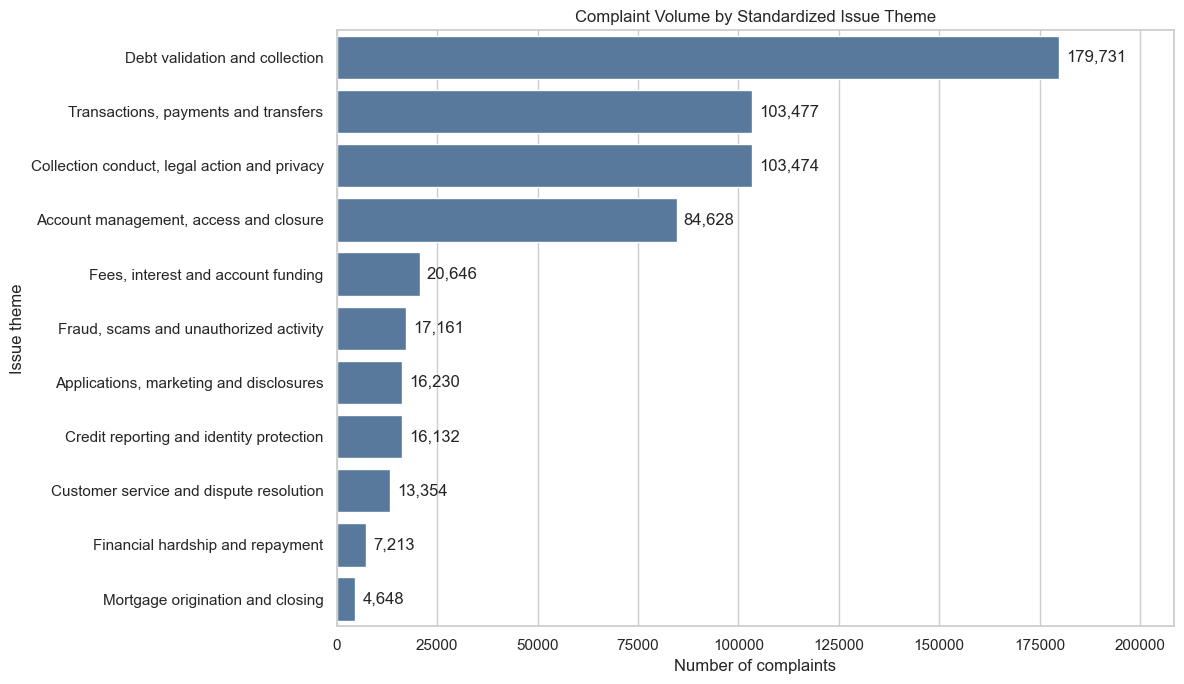

In [17]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=theme_distribution,
    x="complaints",
    y="issue_theme",
    color="#4C78A8"
)

# Add readable complaint counts
label_offset = theme_distribution["complaints"].max() * 0.01

for bar, value in zip(ax.patches, theme_distribution["complaints"]):
    ax.text(
        value + label_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center"
    )

ax.set_xlim(
    0,
    theme_distribution["complaints"].max() * 1.16
)

ax.set_title("Complaint Volume by Standardized Issue Theme")
ax.set_xlabel("Number of complaints")
ax.set_ylabel("Issue theme")

plt.tight_layout()
plt.show()

## 4.6 Equal-Product Issue-Theme Comparison

The balanced dataset is used to compare issue-theme patterns across products without allowing the naturally larger debt collection dataset to dominate the results.

Theme percentages are calculated within each product. This means that every row shows how that product’s complaints are distributed across the standardized themes.

Percentages are used because mortgage contains 24,697 complaints, while the other products contain 30,000 complaints each.

In [18]:
balanced_theme_comparison = (
    balanced_taxonomy_df
    .groupby(["product", "issue_theme"])
    .size()
    .reset_index(name="complaints")
)

# Total complaints within each product
balanced_theme_comparison["product_total"] = (
    balanced_theme_comparison
    .groupby("product")["complaints"]
    .transform("sum")
)

# Percentage distribution within each product
balanced_theme_comparison["share_pct"] = (
    balanced_theme_comparison["complaints"]
    .div(balanced_theme_comparison["product_total"])
    .mul(100)
    .round(2)
)

theme_product_matrix = (
    balanced_theme_comparison
    .pivot(
        index="product",
        columns="issue_theme",
        values="share_pct"
    )
    .fillna(0)
)

display(theme_product_matrix)

issue_theme,"Account management, access and closure","Applications, marketing and disclosures","Collection conduct, legal action and privacy",Credit reporting and identity protection,Customer service and dispute resolution,Debt validation and collection,"Fees, interest and account funding",Financial hardship and repayment,"Fraud, scams and unauthorized activity",Mortgage origination and closing,"Transactions, payments and transfers"
product,,,,,,,,,,,
Checking or savings account,74.04,0.00,0.00,0.45,0.22,0.00,13.79,0.00,0.00,0.00,11.50
Credit card,19.31,15.58,0.00,16.63,11.23,0.00,8.60,1.35,0.00,0.00,27.31
Debt collection,0.00,0.00,36.47,0.00,0.00,63.53,0.00,0.00,0.00,0.00,0.00
"Money transfer, virtual currency, or money service",5.86,2.84,0.00,0.00,3.15,0.00,0.99,0.00,20.13,0.00,67.02
Mortgage,0.00,0.00,0.00,3.81,1.81,0.00,0.00,24.21,0.00,18.82,51.34


### Product-Level Taxonomy Findings

The balanced comparison reveals distinct issue patterns across the five financial products:

- **Checking or savings accounts:** 74.04% of complaints concern account management, access or closure.
- **Credit cards:** complaints are more widely distributed, led by transactions and payments at 27.31%, followed by account management, credit reporting and applications.
- **Debt collection:** 63.53% concern debt validation, while 36.47% involve collection conduct, legal action or privacy.
- **Money transfers:** 67.02% concern transactions, payments or transfers, while 20.13% involve fraud, scams or unauthorized activity.
- **Mortgages:** 51.34% concern payment transactions or servicing, followed by financial hardship at 24.21% and mortgage origination or closing at 18.82%.

The balanced dataset therefore shows the dominant operational risks within each product without allowing debt collection’s larger original volume to distort the comparison.

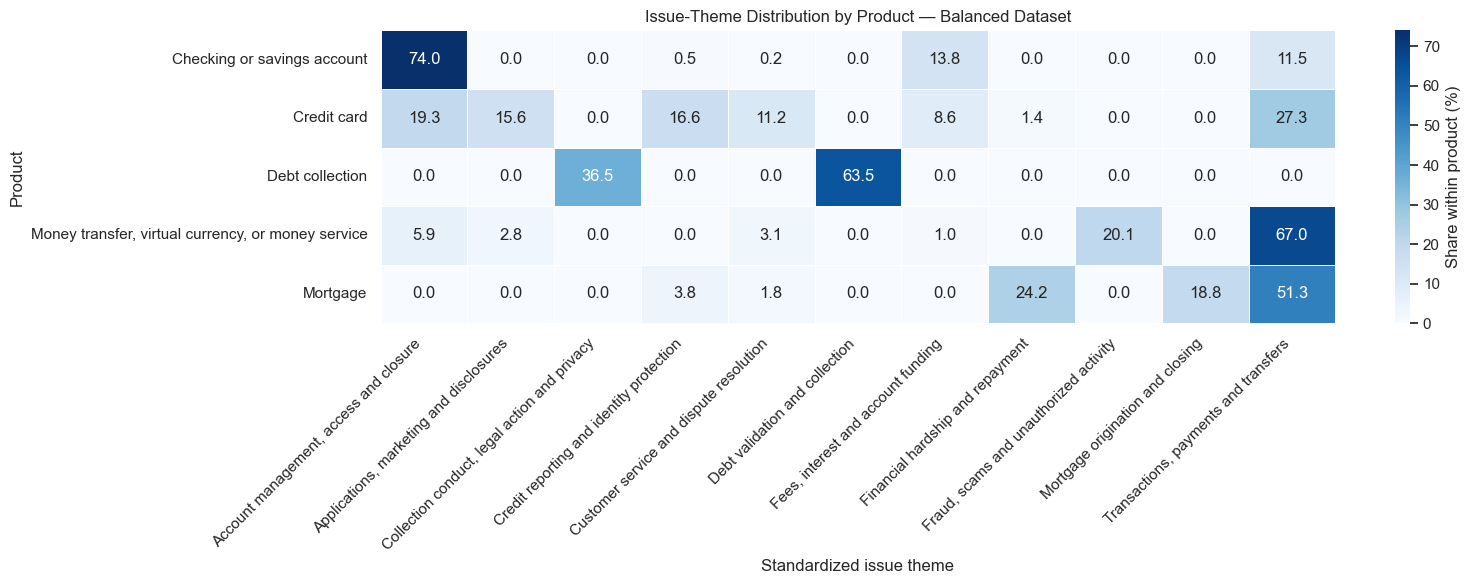

In [19]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    theme_product_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Share within product (%)"}
)

plt.title("Issue-Theme Distribution by Product — Balanced Dataset")
plt.xlabel("Standardized issue theme")
plt.ylabel("Product")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 4.7 Taxonomy Validation

Before exporting the enriched datasets, the taxonomy is validated to ensure that:

- no rows were added or removed;
- every complaint received an issue theme;
- every complaint received an issue-detail label;
- each original issue maps to exactly one standardized theme;
- both datasets use the same taxonomy structure.

In [20]:
# Check whether each original issue maps to only one theme
issue_mapping_consistency = (
    full_taxonomy_df
    .groupby("issue")["issue_theme"]
    .nunique()
)

validation_summary = pd.DataFrame({
    "dataset": ["Full dataset", "Balanced dataset"],
    "original_rows": [
        len(full_df),
        len(balanced_df)
    ],
    "taxonomy_rows": [
        len(full_taxonomy_df),
        len(balanced_taxonomy_df)
    ],
    "missing_issue_theme": [
        full_taxonomy_df["issue_theme"].isna().sum(),
        balanced_taxonomy_df["issue_theme"].isna().sum()
    ],
    "missing_issue_detail": [
        full_taxonomy_df["issue_detail"].isna().sum(),
        balanced_taxonomy_df["issue_detail"].isna().sum()
    ],
    "unique_themes": [
        full_taxonomy_df["issue_theme"].nunique(),
        balanced_taxonomy_df["issue_theme"].nunique()
    ]
})

validation_summary["row_count_preserved"] = (
    validation_summary["original_rows"]
    == validation_summary["taxonomy_rows"]
)

display(validation_summary)

print(
    "Maximum themes assigned to one original issue:",
    issue_mapping_consistency.max()
)

# Final integrity checks
assert validation_summary["row_count_preserved"].all()
assert validation_summary["missing_issue_theme"].eq(0).all()
assert validation_summary["missing_issue_detail"].eq(0).all()
assert issue_mapping_consistency.max() == 1

print("All taxonomy validation checks passed.")

,dataset,original_rows,taxonomy_rows,missing_issue_theme,missing_issue_detail,unique_themes,row_count_preserved
0,Full dataset,566694,566694,0,0,11,True
1,Balanced dataset,144697,144697,0,0,11,True


Maximum themes assigned to one original issue: 1
All taxonomy validation checks passed.


## 4.8 Saving Taxonomy Outputs

The validated taxonomy is saved in three principal outputs:

- the full cleaned dataset enriched with taxonomy fields;
- the balanced dataset enriched with the same taxonomy;
- an auditable mapping table showing every product, issue, sub-issue and standardized theme.

The original Notebook 2 datasets remain unchanged.

In [21]:
taxonomy_mapping = (
    full_taxonomy_df
    .groupby(
        [
            "product",
            "issue_theme",
            "issue",
            "sub_issue",
            "issue_detail"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="complaints")
    .sort_values(
        ["product", "issue_theme", "complaints"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

display(taxonomy_mapping.head(15))

,product,issue_theme,issue,sub_issue,issue_detail,complaints
0,Checking or savings account,"Account management, access and closure",Managing an account,Deposits and withdrawals,Deposits and withdrawals,17379
1,Checking or savings account,"Account management, access and closure",Managing an account,Problem using a debit or ATM card,Problem using a debit or ATM card,9792
2,Checking or savings account,"Account management, access and closure",Managing an account,Funds not handled or disbursed as instructed,Funds not handled or disbursed as instructed,5217
3,Checking or savings account,"Account management, access and closure",Closing an account,Company closed your account,Company closed your account,5040
4,Checking or savings account,"Account management, access and closure",Managing an account,Banking errors,Banking errors,4261
5,Checking or savings account,"Account management, access and closure",Closing an account,Funds not received from closed account,Funds not received from closed account,3466
6,Checking or savings account,"Account management, access and closure",Managing an account,Problem accessing account,Problem accessing account,3395
7,Checking or savings account,"Account management, access and closure",Managing an account,Problem making or receiving payments,Problem making or receiving payments,2741
8,Checking or savings account,"Account management, access and closure",Opening an account,Unable to open an account,Unable to open an account,2665
9,Checking or savings account,"Account management, access and closure",Opening an account,Account opened without my consent or knowledge,Account opened without my consent or knowledge,2564


In [22]:
from pathlib import Path

processed_dir = Path("../data/processed")
output_dir = Path("../outputs/notebook_4_taxonomy")

processed_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

# Enriched datasets
full_taxonomy_path = (
    processed_dir / "cleaned_full_with_taxonomy.csv"
)

balanced_taxonomy_path = (
    processed_dir / "balanced_data_with_taxonomy.csv"
)

full_taxonomy_df.to_csv(
    full_taxonomy_path,
    index=False
)

balanced_taxonomy_df.to_csv(
    balanced_taxonomy_path,
    index=False
)

# Supporting taxonomy tables
taxonomy_mapping.to_csv(
    output_dir / "issue_taxonomy_mapping.csv",
    index=False
)

theme_distribution.to_csv(
    output_dir / "full_theme_distribution.csv",
    index=False
)

balanced_theme_comparison.to_csv(
    output_dir / "balanced_theme_by_product.csv",
    index=False
)

sub_issue_coverage.to_csv(
    output_dir / "sub_issue_coverage.csv",
    index=False
)

validation_summary.to_csv(
    output_dir / "taxonomy_validation_summary.csv",
    index=False
)

print("Notebook 4 outputs saved successfully.")
print("Full taxonomy dataset:", full_taxonomy_path)
print("Balanced taxonomy dataset:", balanced_taxonomy_path)
print("Supporting tables:", output_dir)

Notebook 4 outputs saved successfully.
Full taxonomy dataset: ../data/processed/cleaned_full_with_taxonomy.csv
Balanced taxonomy dataset: ../data/processed/balanced_data_with_taxonomy.csv
Supporting tables: ../outputs/notebook_4_taxonomy


In [23]:
saved_paths = [
    full_taxonomy_path,
    balanced_taxonomy_path,
    output_dir / "issue_taxonomy_mapping.csv",
    output_dir / "full_theme_distribution.csv",
    output_dir / "balanced_theme_by_product.csv",
    output_dir / "sub_issue_coverage.csv",
    output_dir / "taxonomy_validation_summary.csv"
]

saved_file_check = pd.DataFrame({
    "file": [path.name for path in saved_paths],
    "exists": [path.exists() for path in saved_paths],
    "size_mb": [
        round(path.stat().st_size / (1024 ** 2), 2)
        if path.exists() else None
        for path in saved_paths
    ]
})

display(saved_file_check)

assert saved_file_check["exists"].all()

print("All Notebook 4 files verified successfully.")

,file,exists,size_mb
0,cleaned_full_with_taxonomy.csv,True,763.96
1,balanced_data_with_taxonomy.csv,True,232.15
2,issue_taxonomy_mapping.csv,True,0.04
3,full_theme_distribution.csv,True,0.00
4,balanced_theme_by_product.csv,True,0.00
5,sub_issue_coverage.csv,True,0.00
6,taxonomy_validation_summary.csv,True,0.00


All Notebook 4 files verified successfully.


# Notebook 4 Completion Summary

Notebook 4 developed a standardized issue and sub-issue taxonomy for the CFPB complaint data.

### Work completed

- Reviewed the issue distribution for all five financial products.
- Assessed sub-issue availability across every product–issue combination.
- Found approximately 85% overall sub-issue coverage.
- Created `issue_detail`, using the original sub-issue when available and the issue as a fallback.
- Consolidated 47 original CFPB issue labels into 11 standardized issue themes.
- Applied the same taxonomy to the full and balanced datasets.
- Used the full dataset to measure real issue-theme volumes.
- Used the balanced dataset for equal-product comparisons.
- Validated that all rows received exactly one theme and one issue-detail label.
- Confirmed that no records were added, removed or lost.

### Taxonomy hierarchy

1. Product  
2. Standardized issue theme  
3. Original CFPB issue  
4. Sub-issue or issue-detail fallback  

### Principal findings

Debt validation and collection was the largest theme in the full dataset. However, the balanced analysis revealed distinct product-specific complaint profiles:

- checking and savings complaints were dominated by account management;
- credit-card complaints were distributed across several operational themes;
- debt-collection complaints focused on debt validation and collection conduct;
- money-transfer complaints focused on transactions and fraud;
- mortgage complaints focused on servicing, repayment hardship and origination.

### Final enriched datasets

- `cleaned_full_with_taxonomy.csv`
- `balanced_data_with_taxonomy.csv`

These datasets are now ready for narrative-based NLP analysis in Notebook 5.

# Notebook 4 Summary: Issue and Sub-Issue Taxonomy

## Objective

The purpose of Notebook 4 was to transform the original CFPB issue and sub-issue labels into a consistent analytical taxonomy. This enables complaint themes to be compared across financial products while preserving the original CFPB classifications.

The full dataset was used for actual complaint volumes, while the balanced dataset was used only for equal-product comparisons.

---

## 1. Dataset preparation

The two cleaned datasets created in Notebook 2 were loaded:

- Full cleaned dataset: **566,694 complaints**
- Balanced analytical dataset: **144,697 complaints**

No additional cleaning, resampling or deletion was performed.

---

## 2. Original issue inventory

Complaint counts were calculated for every product–issue combination.

The leading issue for each product was:

- **Checking or savings account:** Managing an account — 44,959 complaints
- **Credit card:** Problem with a purchase shown on your statement — 19,810
- **Debt collection:** Attempts to collect debt not owed — 115,682
- **Money transfer:** Other transaction problem — 53,893
- **Mortgage:** Trouble during payment process — 12,680

This showed that each financial product has a distinct issue structure.

---

## 3. Sub-issue coverage assessment

Sub-issue availability was examined for every product–issue combination.

Approximately **85% of all complaints contained a sub-issue**. Coverage was nearly complete for checking accounts, credit cards, debt collection and mortgages.

The main exception was money transfer:

- All **84,619 money-transfer complaints** lacked sub-issues.
- An additional 158 fraud-alert or security-freeze complaints lacked sub-issues.
- No records were removed because of missing sub-issues.

---

## 4. Issue-detail construction

A new field called `issue_detail` was created:

- If a sub-issue was available, `issue_detail` used the sub-issue.
- If the sub-issue was missing, it used the original issue as a fallback.

A Boolean field called `sub_issue_available` was also created to record whether the original complaint contained sub-issue information.

This ensured that every complaint received a detailed label without inventing or imputing information.

---

## 5. Standardized issue taxonomy

The dataset contained **47 unique original issue labels**. These labels were manually grouped into **11 standardized issue themes**:

1. Account management, access and closure  
2. Applications, marketing and disclosures  
3. Collection conduct, legal action and privacy  
4. Credit reporting and identity protection  
5. Customer service and dispute resolution  
6. Debt validation and collection  
7. Fees, interest and account funding  
8. Financial hardship and repayment  
9. Fraud, scams and unauthorized activity  
10. Mortgage origination and closing  
11. Transactions, payments and transfers  

The mapping was transparent and rule-based. The original issue and sub-issue columns were retained.

The final taxonomy hierarchy was:

1. Product  
2. Standardized issue theme  
3. Original CFPB issue  
4. Sub-issue or issue-detail fallback  

---

## 6. Full-dataset theme analysis

The full dataset was used to measure actual complaint volume.

The largest themes were:

- **Debt validation and collection:** 179,731 complaints — 31.72%
- **Transactions, payments and transfers:** 103,477 — 18.26%
- **Collection conduct, legal action and privacy:** 103,474 — 18.26%
- **Account management, access and closure:** 84,628 — 14.93%

Together, these four themes represented approximately **83.2%** of all complaints.

Because debt collection was the largest product in the original dataset, these results describe real volume rather than equal product importance.

---

## 7. Equal-product comparison

The balanced dataset was used to compare theme distributions across products. Percentages were calculated within each product because mortgage contained 24,697 records while the other products contained 30,000 each.

The principal findings were:

- **Checking or savings:** 74.04% account management, access and closure
- **Credit card:** 27.31% transactions and payments, with complaints distributed across several other themes
- **Debt collection:** 63.53% debt validation and 36.47% collection conduct
- **Money transfer:** 67.02% transactions and transfers; 20.13% fraud and unauthorized activity
- **Mortgage:** 51.34% payment and servicing problems; 24.21% financial hardship; 18.82% origination and closing

A heatmap was created to visualize these product-specific differences.

---

## 8. Taxonomy validation

The completed taxonomy passed all validation checks:

- Full dataset retained all **566,694 rows**
- Balanced dataset retained all **144,697 rows**
- Missing issue themes: **0**
- Missing issue-detail values: **0**
- Unique standardized themes: **11**
- Every original issue mapped to exactly one theme
- No records were added, removed or duplicated

The enriched datasets contain the original 26 columns plus:

- `sub_issue_available`
- `issue_detail`
- `issue_theme`

This produced **29 columns** in each final dataset.

---

## 9. Saved outputs

### Enriched datasets

- `cleaned_full_with_taxonomy.csv`
- `balanced_data_with_taxonomy.csv`

### Supporting analytical tables

- `issue_taxonomy_mapping.csv`
- `full_theme_distribution.csv`
- `balanced_theme_by_product.csv`
- `sub_issue_coverage.csv`
- `taxonomy_validation_summary.csv`

---

## Conclusion

Notebook 4 successfully converted product-specific CFPB complaint labels into a consistent, validated and auditable taxonomy. The new structure supports cross-product analysis while retaining the original issue and sub-issue information.

The enriched datasets are now ready for **Notebook 5: Consumer Narrative Preparation for NLP**.